# 08 – Performance in kWh/m³ vor und nach der Begehung (Datenbasis Notebook 00)

> **Kopie von Ivelinas Notebook 08 mit anderer Datenbasis.**
> - Daten: `real_meters` aus [`00_eda`](00_eda_hast_stationsprofile.ipynb), also dieselben Zählerreihen wie in [`06`](06_tagesmerkmale_clusteranalyse.ipynb) und [`12_ternaer_nb00`](12_ternaer_nb00.ipynb)
> - Ivelinas Lauf: Rohdaten direkt über `src.load_timeseries`, alle Zähler inkl. BHKW/Kessel, nur CSV bis 11.07.2025
> - hier: 96 HAST, mit ODS-Nachlieferung, aufbereitet wie in Notebook 00
> - Notebook 00 legt ein lückenloses Stundenraster an. Die leeren Rasterzeilen fliegen beim Laden wieder raus: `src` erkennt Lücken am Zeitabstand, mit den leeren Zeilen würde jede fehlende Stunde zwei Intervalle kosten
> - Zeitraum wie NB 06 und 12_ternaer_nb00 bis 31.12.2025, umstellbar über `BIS`
> - ODS-Stunden haben keine Zählerstände. In der Hauptauswertung zählen sie deshalb nicht, Abschnitt 9 ergänzt sie per Integration
> - Rechenweg (`src/performance.py`) unverändert, damit nur die Daten den Unterschied machen
> - Grafiken landen in `outputs/performance_nb00/`, Ivelinas Dateien bleiben unangetastet
> - Textzellen mit Befunden stammen noch aus Ivelinas Lauf
> - **Ergebnis dieses Laufs: letzte Zelle (Abschnitt 11)**


Nachrechnung der ÜZ-Folie „Vergleich Gesamteffizienz vor und nach der Optimierung von HAST" mit unseren Zählerdaten.

- **Kennzahl:** entnommene Energie je m³ Heizwasser, aufgetragen gegen die Außentemperatur
- **Aussage der Folie:** optimierte Stationen liegen rund 2,12 kWh/m³ bzw. 13,4 % höher (bei ca. 8,8 °C)
- **Einordnung:** 1 kWh/m³ ≈ 0,86 K Spreizung. Hoch ist gut, der Rücklauf bleibt kühl.

Was wir zusätzlich zur Folie machen:

- Signifikanztest auf den Steigungsunterschied
- Check, ob beide Gruppen denselben Temperaturbereich abdecken
- zweite Variante mit dem eigenen Begehungsdatum je Station statt einem gemeinsamen Stichtag

Code: `src/performance.py`, Tests: `tests/test_performance.py`

## 1 – Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import performance as perf
from src import load_begehungen as lb
from src import load_timeseries as lts
from src import ternaer as tn
from src import weather

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (10, 6)

METER_DIR = Path.cwd().parent / "data" / "processed" / "real_meters"
OUTPUTS = Path.cwd().parent / "outputs" / "performance_nb00"
OUTPUTS.mkdir(parents=True, exist_ok=True)

### Parameter

- `MIN_VOLUME_M3`: Mindest-Tagesvolumen, darunter ist Energie/Volumen nur Rauschen
- `BAND`: Plausibilitätsband der Kennzahl
- `PUFFER_TAGE`: blendet in Variante B die Einregelphase um die Begehung aus

Wie viel an welchem Filter hängen bleibt, zeigt die Filterbilanz weiter unten.

In [2]:
MIN_VOLUME_M3 = perf.MIN_VOLUME_M3   #0,5 m3 je Tag
BAND = perf.BAND_KWH_M3              #(-2, 70) kWh/m3
MIN_STUNDEN = perf.MIN_STUNDEN       #20 von 24 gueltigen Stundenintervallen
PUFFER_TAGE = 7                      #Einregelphase um die Begehung, Variante B
STICHTAG_UZ = "2024-09-30"           #Stichtag der UEZ-Folie

#Spaltennamen der Rohexporte auf das Schema von features.features_for_meter
SPALTEN = {
    "Energy (kWh)": "energy",
    "Volume flow (l/h)": "flow",
    "Power (kW)": "power",
    "Temperature difference (°C)": "dt",
    "Flow temperature (°C)": "vl",
    "Return temperature (°C)": "rt",
    "Volume (m³)": "volume",
}

#Zeitraum wie Notebook 06 und 12_ternaer_nb00: die DWD-Datei endet am
#31.12.2025, spaetere Tage fallen dort raus. None nimmt alles aus Notebook 00.
BIS = pd.Timestamp("2025-12-31 23:00")

#Erzeuger und Kessel, die Notebook 00 ausschliesst. Tauchen sie auf,
#stammt real_meters nicht aus Notebook 00.
NICHT_HAST = {86792512, 41566330, 41566332, 41566331, 48090145, 41628863}

#Ende der CSV-Exporte. Davor haben alle Zaehler gemessene Zaehlerstaende,
#danach nur die ODS-Nachlieferung ohne Zaehlerstaende.
CSV_ENDE = pd.Timestamp("2025-07-12")


## 2 – Daten laden

- Stundenreihen aus `data/processed/real_meters`, geschrieben von Notebook 00
- leere Rasterzeilen raus (siehe oben), Zeitraum bis `BIS`
- **Gegenprobe zu Notebook 00:** Bis zum 15.10.2026 hat Notebook 00 bei überlappenden Exporten die ODS-Nachlieferung gewinnen lassen, die keine Zählerstände hat. Seitdem gewinnt dort die CSV. Die Tabelle unten zählt die Stunden ohne Zählerstand vor dem Ende der CSV-Exporte, getrennt nach ODS-Zählern und übrigen. Liegt der Anteil bei den ODS-Zählern deutlich höher, stammt `real_meters` noch aus einem Lauf vor dem Fix: Notebook 00 neu ausführen.


In [3]:
def lade_serien_nb00(zaehler=None, bis=BIS):
    """Stundenreihen aus Notebook 00 ohne die leeren Zeilen des Stundenrasters.

    Rueckgabe: Dict Zaehlernummer -> Stundenreihe und ein paar Zaehlwerte
    fuer die Ausgabe.
    """
    roh = tn.lade_serien(METER_DIR, zaehler=zaehler)
    fremd = sorted(set(roh) & NICHT_HAST)
    assert not fremd, (f"real_meters enthaelt Nicht-HAST-Zaehler {fremd}, "
                       "stammt also nicht aus Notebook 00 - Notebook 00 neu ausfuehren")
    messspalten = list(tn.SPALTEN_MAP.values())
    serien = {}
    info = {"leer": 0, "abgeschnitten": 0, "ohne_stand": 0}
    for m, d in roh.items():
        gemessen = d.dropna(how="all",
                            subset=[c for c in messspalten if c in d.columns])
        info["leer"] += len(d) - len(gemessen)
        if bis is not None:
            info["abgeschnitten"] += int((gemessen.index > bis).sum())
            gemessen = gemessen[gemessen.index <= bis]
        info["ohne_stand"] += int(gemessen["energy"].isna().sum())
        serien[m] = gemessen
    return serien, info


def integriert(d):
    """Fehlende Zaehlerstaende aus Leistung und Volumenstrom integrieren."""
    rueck = {v: k for k, v in tn.SPALTEN_MAP.items()}
    roh = d.rename(columns=rueck).rename_axis("Timestamp").reset_index()
    return (lts.ergaenze_zaehlerstaende(roh)
            .rename(columns=tn.SPALTEN_MAP).set_index("Timestamp"))


serien, info = lade_serien_nb00()
hist_von = min(d.index[0].normalize() for d in serien.values() if len(d))
hist_bis = max(d.index[-1].normalize() for d in serien.values() if len(d))
ODS_METER = sorted(lts.discover_meter_ods())

print(f"{len(serien)} Zaehlerreihen aus Notebook 00")
print(f"Historie insgesamt: {hist_von.date()} .. {hist_bis.date()}")
print(f"{info['leer']:,} leere Rasterzeilen entfernt, "
      f"{info['abgeschnitten']:,} gemessene Stunden nach BIS abgeschnitten")
print(f"{sum(len(d) for d in serien.values()):,} gemessene Stunden, "
      f"davon {info['ohne_stand']:,} ohne Zaehlerstand")

#Gegenprobe: Stunden ohne Zaehlerstand vor dem Ende der CSV-Exporte
zeilen = []
for gruppe, auswahl in (("ODS-Zaehler", [m for m in serien if m in ODS_METER]),
                        ("uebrige", [m for m in serien if m not in ODS_METER])):
    vor = [serien[m][serien[m].index < CSV_ENDE] for m in auswahl]
    zeilen.append({"gruppe": gruppe, "zaehler": len(auswahl),
                   "stunden": sum(len(d) for d in vor),
                   "ohne_stand": sum(int(d["energy"].isna().sum()) for d in vor)})
stand = pd.DataFrame(zeilen)
stand["anteil_ohne_stand"] = stand["ohne_stand"] / stand["stunden"]
display(stand.round(3))


93 Zaehlerreihen aus Notebook 00
Historie insgesamt: 2021-11-01 .. 2025-12-31
0 leere Rasterzeilen entfernt, 24,054 gemessene Stunden nach BIS abgeschnitten
1,670,077 gemessene Stunden, davon 7 ohne Zaehlerstand


,gruppe,zaehler,stunden,ohne_stand,anteil_ohne_stand
0,ODS-Zaehler,5,102087,0,0.0
1,uebrige,88,1547237,0,0.0


In [4]:
t_out = weather.load_outdoor_temperature(hist_von,
                                         hist_bis + pd.Timedelta(hours=23),
                                         allow_download=False)
print(f"Aussentemperatur: {len(t_out)} Stunden, "
      f"{int(t_out['interpolated'].sum())} davon interpoliert")

begehungen = (lb.begehungen_mit_zaehler(available=set(serien))
                .dropna(subset=["meter", "datum"]))
begehungen["meter"] = begehungen["meter"].astype(int)
#bei mehreren Begehungen je Station trennt die erste
erste_begehung = begehungen.sort_values("datum").groupby("meter")["datum"].first()

print(f"{len(begehungen)} Begehungen mit Zaehlernummer, "
      f"{begehungen['meter'].nunique()} Zaehler")
display(begehungen["datum"].dt.to_period("M").value_counts().sort_index()
        .rename("Begehungen").to_frame())

Aussentemperatur: 36524 Stunden, 7 davon interpoliert


/Users/seb/miniconda3/envs/projektseminar/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


58 Begehungen mit Zaehlernummer, 56 Zaehler


,Begehungen
datum,
2024-08,2
2024-09,34
2024-10,3
2024-11,13
2024-12,1
2025-03,1
2025-09,4


> *Befundtext aus Ivelinas Lauf (Rohdaten direkt über `src.load_timeseries`, alle Zähler inkl. BHKW/Kessel, nur CSV bis 11.07.2025). Zahlen noch nicht an diesen Lauf angepasst.*

**Stichtag:** Der Stichtag der Folie (2024-09-30) passt auch bei uns.

- 36 von 58 Begehungen liegen davor, Median ist der 2024-09-20
- Problem: vier Begehungen vom September 2025 liegen hinter dem Ende der Zählerhistorie (2025-07-11). Diese Stationen haben keine Nachher-Phase, landen beim festen Stichtag aber trotzdem in „optimiert".
- Deshalb gibt es Variante B.

## 3 – Kennzahl aus den kumulativen Kanälen

Energie und Volumen sind Zählerstände, die Tageswerte entstehen aus Stundendifferenzen. Einzelne Stundenintervalle fliegen raus bei:

- Rücksprung des Zählerstands (Überlauf, Gerätetausch)
- Intervall über eine Messlücke
- physikalisch unmöglichem Sprung nach vorn

Der restliche Tag bleibt drin.

In [5]:
tab = perf.performance_tabelle(serien, min_volume_m3=MIN_VOLUME_M3,
                               band=BAND, min_stunden=MIN_STUNDEN)
tab = perf.mit_aussentemperatur(tab, t_out)
print(f"{len(tab):,} Stationstage aus {tab['meter'].nunique()} Zaehlern")
display(perf.filterbilanz(tab))

84,981 Stationstage aus 93 Zaehlern


,bedingung,tage,anteil
0,Tagesreihen gesamt,84981,1.000000
1,Volumen unter Schwelle,26128,0.307457
2,ausserhalb Plausibilitaetsband,0,0.000000
3,Abdeckung unter Mindeststunden,16116,0.189642
4,gueltig,58765,0.691508


> *Befundtext aus Ivelinas Lauf (Rohdaten direkt über `src.load_timeseries`, alle Zähler inkl. BHKW/Kessel, nur CSV bis 11.07.2025). Zahlen noch nicht an diesen Lauf angepasst.*

- Knapp 62 % der Stationstage bleiben übrig.
- Größter Posten: Tage unter der Volumenschwelle (Sommer, Stillstand).
- Das Plausibilitätsband greift bei keinem einzigen Tag.

### Gegenprobe gegen die gemessene Spreizung

Die Kennzahl in Kelvin umgerechnet muss ungefähr zur gemessenen, durchflussgewichteten Spreizung passen. Wenn nicht, stimmen Energie-, Volumen- und Temperaturkanal des Zählers nicht zusammen.

In [6]:
gegen = tab[tab["gueltig"]].dropna(subset=["dt_abweichung_k"])
print(gegen["dt_abweichung_k"].describe()[["count", "mean", "50%", "std"]])

je_meter = (gegen.groupby("meter")["dt_abweichung_k"]
            .agg(["median", "count"])
            .sort_values("median"))
auffaellig = je_meter[je_meter["median"].abs() > 3.0]
print(f"\nZaehler mit Medianabweichung ueber 3 K: {len(auffaellig)} "
      f"von {len(je_meter)}")
display(auffaellig)

count    56810.000000
mean        -1.258219
50%         -0.514396
std          4.644434
Name: dt_abweichung_k, dtype: float64

Zaehler mit Medianabweichung ueber 3 K: 11 von 93


,median,count
meter,,
53198226,-7.083191,884
68956355,-6.201846,934
68956360,-5.608822,948
72167782,-3.852563,945
72135442,-3.670143,970
72167793,-3.497079,544
68956372,-3.239816,1043
72135490,-3.168759,852
80912182,-3.058641,562


> *Befundtext aus Ivelinas Lauf (Rohdaten direkt über `src.load_timeseries`, alle Zähler inkl. BHKW/Kessel, nur CSV bis 11.07.2025). Zahlen noch nicht an diesen Lauf angepasst.*

- Abweichung im Median rund 0,5 K, das passt zur stündlichen Abtastung.
- Die auffälligen Zähler bleiben hier erstmal drin. Die Ursache ist nicht geklärt, ein Ausschluss würde nur die Fallzahl senken.

## 4 – Zwei Auswertungsvarianten

- **Variante A:** ein gemeinsamer Stichtag für alle Stationen (wie auf der Folie)
- **Variante B:** jede Station bekommt ihr eigenes Begehungsdatum als Trennpunkt

Warum B: Unsere Begehungen verteilen sich über 13 Monate. Mit einem gemeinsamen Stichtag landen Tage in der falschen Gruppe.

Grundmenge für beide: gültige Stationstage von Stationen mit dokumentierter Begehung.

In [7]:
basis = tab[tab["gueltig"] & tab["meter"].isin(erste_begehung.index)].copy()
basis = basis.dropna(subset=["t_out_tag"])
print(f"Grundmenge: {len(basis):,} Stationstage, "
      f"{basis['meter'].nunique()} Zaehler")

var_a = perf.gruppe_fester_stichtag(basis, STICHTAG_UZ)
var_b = perf.gruppe_je_station(basis, erste_begehung.to_dict(),
                               puffer_tage=PUFFER_TAGE)
ohne_gruppe = int(var_b["gruppe"].isna().sum())
var_b = var_b.dropna(subset=["gruppe"])

print(f"Variante A: {len(var_a):,} Tage")
print(f"Variante B: {len(var_b):,} Tage, {ohne_gruppe} Tage im Puffer "
      f"von +/- {PUFFER_TAGE} Tagen um die Begehung ausgeblendet")

Grundmenge: 31,543 Stationstage, 51 Zaehler
Variante A: 31,543 Tage
Variante B: 31,059 Tage, 484 Tage im Puffer von +/- 7 Tagen um die Begehung ausgeblendet


## 5 – Regression je Gruppe

In [8]:
def auswerten(daten, name):
    """Beide Geraden, Bezugspunkt, Delta und Interaktionstest in einem Schritt."""
    fits = perf.regression_je_gruppe(daten, cluster="meter")
    t_ref = float(pd.to_numeric(daten["t_out_tag"], errors="coerce").mean())
    zeile = fits.set_index("gruppe")
    delta = perf.delta_am_bezugspunkt(
        zeile.loc[perf.GRUPPE_VOR, "steigung"],
        zeile.loc[perf.GRUPPE_VOR, "achsenabschnitt"],
        zeile.loc[perf.GRUPPE_NACH, "steigung"],
        zeile.loc[perf.GRUPPE_NACH, "achsenabschnitt"],
        t_ref)
    modell = perf.interaktionsmodell(daten, cluster="meter")
    delta_ci = perf.delta_aus_interaktion(modell, t_ref)
    print(f"--- {name} --- Bezugspunkt {t_ref:.2f} °C")
    return {"name": name, "daten": daten, "fits": fits, "t_ref": t_ref,
            "delta": delta, "modell": modell, "delta_ci": delta_ci}


erg_a = auswerten(var_a, "Variante A (fester Stichtag)")
erg_b = auswerten(var_b, "Variante B (stationseigenes Begehungsdatum)")

spalten = ["gruppe", "n", "meter", "steigung", "steigung_ci_low",
           "steigung_ci_high", "achsenabschnitt", "r2", "t_out_mittel"]
for erg in (erg_a, erg_b):
    print(f"\n{erg['name']}")
    display(erg["fits"][spalten].round(3))

--- Variante A (fester Stichtag) --- Bezugspunkt 9.67 °C
--- Variante B (stationseigenes Begehungsdatum) --- Bezugspunkt 9.63 °C

Variante A (fester Stichtag)


,gruppe,n,meter,steigung,steigung_ci_low,steigung_ci_high,achsenabschnitt,r2,t_out_mittel
0,unoptimiert,19557,49,-0.716,-0.884,-0.549,29.056,0.196,10.692
1,optimiert,11986,48,-0.655,-0.797,-0.514,30.083,0.162,8.012



Variante B (stationseigenes Begehungsdatum)


,gruppe,n,meter,steigung,steigung_ci_low,steigung_ci_high,achsenabschnitt,r2,t_out_mittel
0,unoptimiert,20166,49,-0.736,-0.926,-0.547,29.361,0.201,10.464
1,optimiert,10893,47,-0.614,-0.716,-0.512,29.719,0.158,8.094


**Konfidenzintervalle:** clusterrobust mit der Zählernummer als Cluster. Tage derselben Station sind nicht unabhängig, die Standardformel liefert hier Standardfehler, die etwa um Faktor fünf zu eng sind.

In [9]:
zeilen = []
for erg in (erg_a, erg_b):
    d, m, ci = erg["delta"], erg["modell"], erg["delta_ci"]
    zeilen.append({
        "Variante": erg["name"],
        "t_ref (°C)": erg["t_ref"],
        "y unoptimiert": d["y_vor"],
        "y optimiert": d["y_nach"],
        "Delta (kWh/m³)": d["delta_kwh_m3"],
        "Delta (K)": d["delta_k"],
        "Delta (%)": d["delta_prozent"],
        "Delta KI unten": ci["delta_ci"][0],
        "Delta KI oben": ci["delta_ci"][1],
        "Delta p": ci["delta_p"],
        "Steigungsdiff.": m["steigungsdifferenz"],
        "Steigungsdiff. p": m["steigungsdifferenz_p"],
        "n": m["n"],
        "Stationen": m["n_cluster"],
    })
ergebnis = pd.DataFrame(zeilen)
display(ergebnis.round(4).set_index("Variante").T)

Variante,Variante A (fester Stichtag),Variante B (stationseigenes Begehungsdatum)
t_ref (°C),9.6736,9.6326
y unoptimiert,22.1283,22.2708
y optimiert,23.7450,23.8049
Delta (kWh/m³),1.6168,1.5342
Delta (K),1.3902,1.3191
Delta (%),7.3064,6.8887
Delta KI unten,-0.0653,-0.3047
Delta KI oben,3.2989,3.3730
Delta p,0.0592,0.1000
Steigungsdiff.,0.0610,0.1221


> *Befundtext aus Ivelinas Lauf (Rohdaten direkt über `src.load_timeseries`, alle Zähler inkl. BHKW/Kessel, nur CSV bis 11.07.2025). Zahlen noch nicht an diesen Lauf angepasst.*

**Ergebnis:**

- Der **Höhenabstand** der Geraden am Bezugspunkt ist in beiden Varianten klar von null verschieden.
- Der Unterschied der **Steigungen** ist es nicht: Variante A 0,02 (p ≈ 0,79), Variante B 0,09 (p ≈ 0,35).
- „Optimierte Anlagen fallen im Milden flacher ab" lässt sich mit unseren Daten also nicht belegen, der Niveauunterschied schon.

### Gegenprobe mit Volumengewichtung

Die Folie zeichnet die Blasen nach Volumen, fittet aber offenbar ungewichtet. Hier derselbe Fit gewichtet mit dem Tagesvolumen.

In [10]:
for erg in (erg_a, erg_b):
    gew = perf.regression_je_gruppe(erg["daten"], gewicht="volumen_m3",
                                    cluster="meter")
    print(f"\n{erg['name']} – mit Tagesvolumen gewichtet")
    display(gew[["gruppe", "n", "steigung", "achsenabschnitt", "r2"]].round(3))


Variante A (fester Stichtag) – mit Tagesvolumen gewichtet


,gruppe,n,steigung,achsenabschnitt,r2
0,unoptimiert,19557,-0.826,23.391,0.229
1,optimiert,11986,-0.805,27.115,0.161



Variante B (stationseigenes Begehungsdatum) – mit Tagesvolumen gewichtet


,gruppe,n,steigung,achsenabschnitt,r2
0,unoptimiert,20166,-0.831,23.644,0.225
1,optimiert,10893,-0.803,27.024,0.167


> *Befundtext aus Ivelinas Lauf (Rohdaten direkt über `src.load_timeseries`, alle Zähler inkl. BHKW/Kessel, nur CSV bis 11.07.2025). Zahlen noch nicht an diesen Lauf angepasst.*

- Volumengewichtet fällt die optimierte Gerade sogar etwas steiler ab als die unoptimierte.
- Der Höhenabstand bleibt.
- Die Steigungsaussage hängt also an der Gewichtung, nicht an den Anlagen.

## 6 – Decken beide Gruppen denselben Temperaturbereich ab?

Fehlt auf der Folie. Liegen die beiden Punktwolken auf unterschiedlichen Temperaturbereichen, vergleicht man verschiedene Betriebsbereiche und der Wert am Bezugspunkt wäre extrapoliert.

In [11]:
for erg in (erg_a, erg_b):
    print(f"\n{erg['name']}")
    display(perf.temperaturueberdeckung(erg["daten"],
                                        t_ref=erg["t_ref"]).round(2))


Variante A (fester Stichtag)


,gruppe,n,mittel,q05,q25,q50,q75,q95,n_nahe_t_ref,anteil_nahe_t_ref,t_ref_im_bereich
0,unoptimiert,19557,10.69,-1.27,5.91,10.03,16.51,22.24,4350,0.22,True
1,optimiert,11986,8.01,-1.60,2.84,6.99,12.40,21.20,2288,0.19,True



Variante B (stationseigenes Begehungsdatum)


,gruppe,n,mittel,q05,q25,q50,q75,q95,n_nahe_t_ref,anteil_nahe_t_ref,t_ref_im_bereich
0,unoptimiert,20166,10.46,-1.48,5.63,9.78,16.22,22.23,4616,0.23,True
1,optimiert,10893,8.09,-1.60,2.84,7.12,12.51,21.20,2040,0.19,True


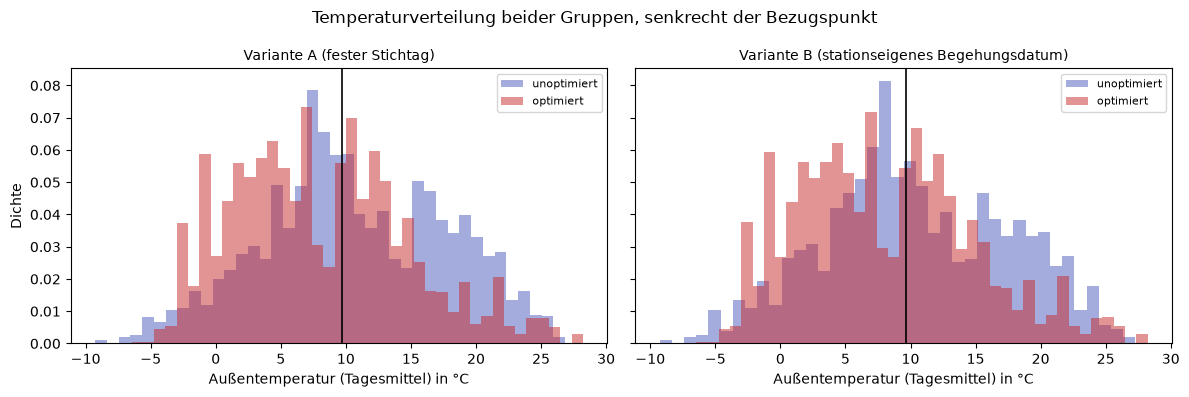

In [12]:
fig, achsen = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, erg in zip(achsen, (erg_a, erg_b)):
    for name, farbe in ((perf.GRUPPE_VOR, "#4b5bbf"),
                        (perf.GRUPPE_NACH, "#c62828")):
        werte = erg["daten"].loc[erg["daten"]["gruppe"] == name, "t_out_tag"]
        ax.hist(werte, bins=40, alpha=0.5, color=farbe, label=name,
                density=True)
    ax.axvline(erg["t_ref"], color="black", linewidth=1.2)
    ax.set_title(erg["name"], fontsize=10)
    ax.set_xlabel("Außentemperatur (Tagesmittel) in °C")
    ax.legend(fontsize=8)
achsen[0].set_ylabel("Dichte")
fig.suptitle("Temperaturverteilung beider Gruppen, senkrecht der Bezugspunkt")
fig.tight_layout()
plt.show()

> *Befundtext aus Ivelinas Lauf (Rohdaten direkt über `src.load_timeseries`, alle Zähler inkl. BHKW/Kessel, nur CSV bis 11.07.2025). Zahlen noch nicht an diesen Lauf angepasst.*

- Der Bezugspunkt liegt in beiden Gruppen und Varianten im belegten Bereich, rund ein Fünftel der Tage liegt im Band ±2 K. Es wird nichts extrapoliert.
- Die Gruppe „optimiert" ist aber im Mittel 2,7 bis 3,1 K kälter, ihr unteres Quartil beginnt bei knapp 3 °C statt 6 °C.
- Für den Höhenabstand am Bezugspunkt ist das unkritisch.
- Für die Steigungen nicht: die unoptimierte Gerade hängt stärker am warmen Ende, die optimierte am kalten. Ein Teil des Steigungsunterschieds der Folie kann allein daher kommen.

## 7 – Die Grafik

Knapp 29 000 Tagespunkte ergeben als Streudiagramm nur eine Farbfläche. Deshalb:

- **Hauptgrafik:** ein Punkt je Station, Gruppe und 2-K-Temperaturklasse. Höhe = volumengewichtetes Mittel der Kennzahl, Fläche = Volumen.
- Die Regressionsgeraden kommen weiterhin aus dem Fit über die Tageswerte.
- **Darunter:** dieselbe Auswertung unverdichtet auf Tagesebene.

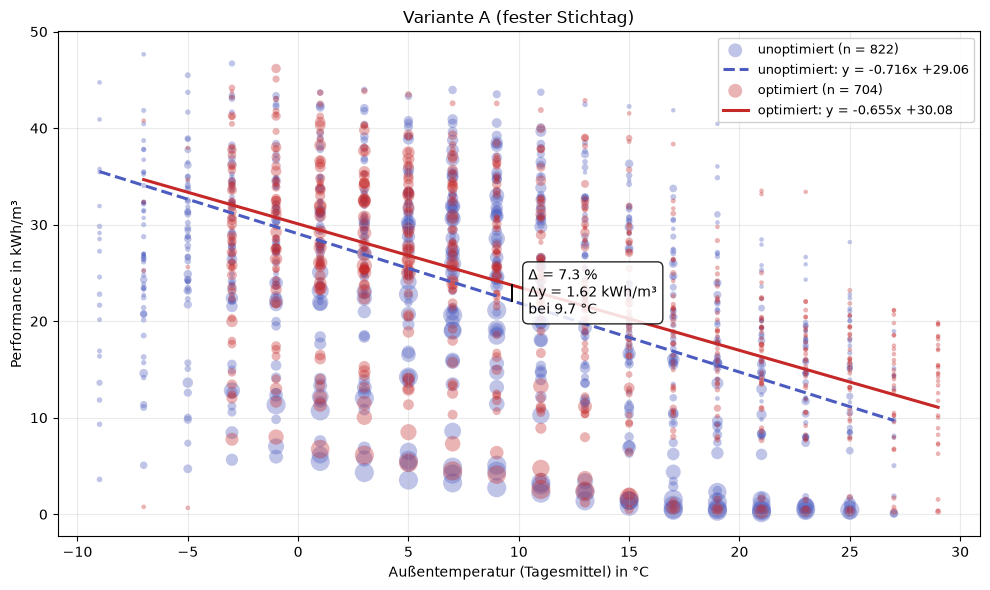

1526 Blasen aus 31,543 Stationstagen -> outputs/performance_variante_a.png


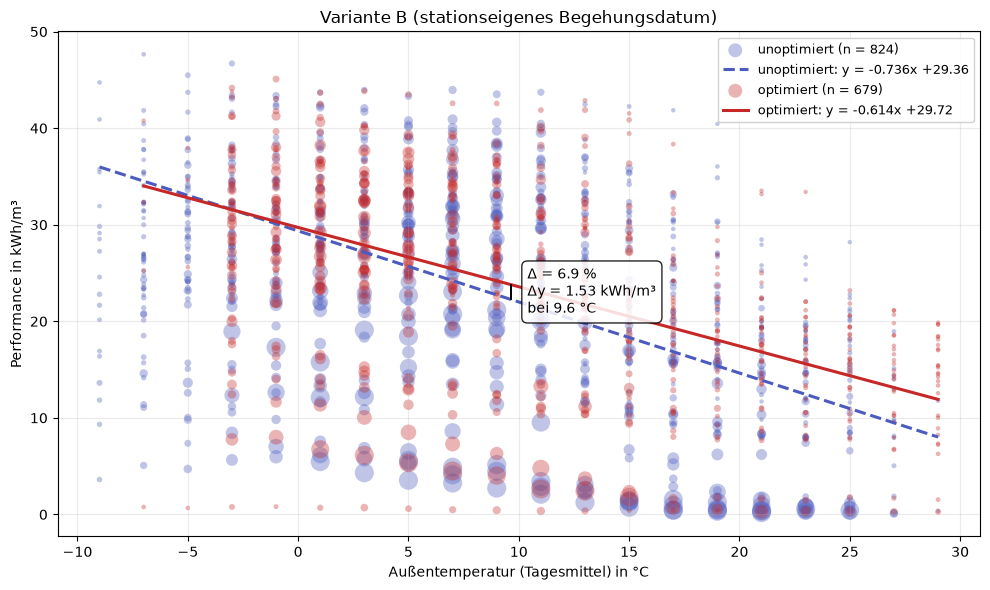

1503 Blasen aus 31,059 Stationstagen -> outputs/performance_variante_b.png


In [13]:
KLASSENBREITE = 2.0   #Temperaturklasse der Blasendarstellung in K

for erg, datei in ((erg_a, "performance_variante_a.png"),
                   (erg_b, "performance_variante_b.png")):
    blasen = perf.blasen_aggregat(erg["daten"], klassenbreite=KLASSENBREITE)
    fig, ax = plt.subplots(figsize=(10, 6))
    perf.blasendiagramm(blasen, erg["fits"], erg["t_ref"],
                        delta=erg["delta"], titel=erg["name"], ax=ax)
    fig.tight_layout()
    fig.savefig(OUTPUTS / datei, dpi=150)
    plt.show()
    print(f"{len(blasen)} Blasen aus {len(erg['daten']):,} Stationstagen "
          f"-> outputs/{datei}")

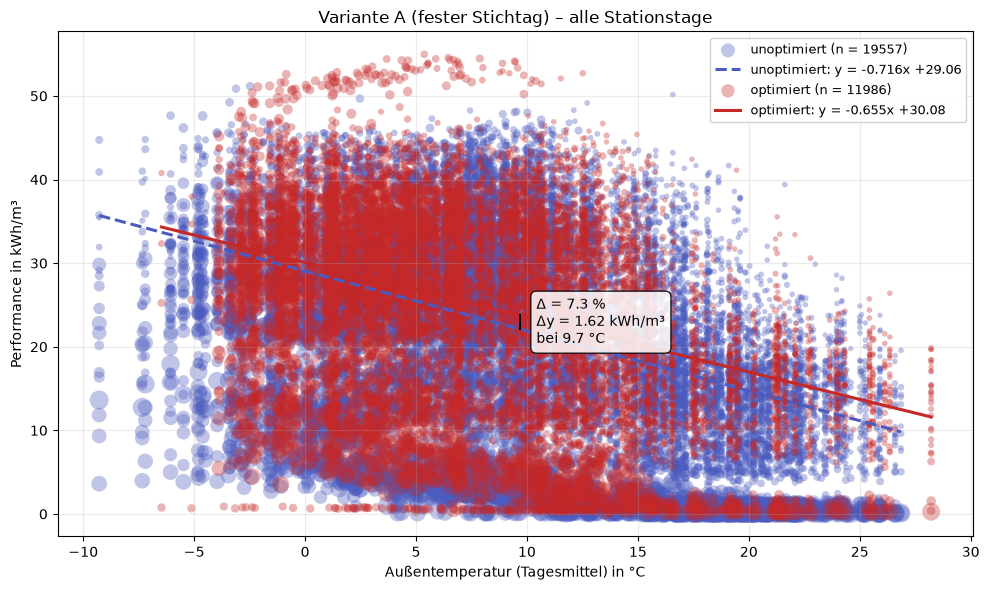

gespeichert: outputs/performance_variante_a_tage.png


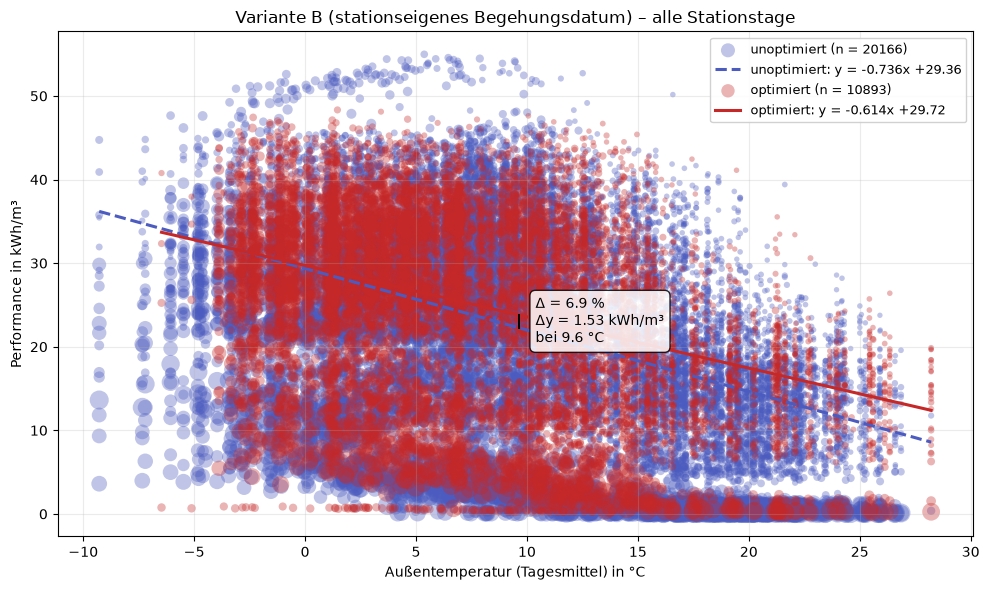

gespeichert: outputs/performance_variante_b_tage.png


In [14]:
#Gegenprobe ohne Verdichtung: dieselben Geraden auf allen Tageswerten
for erg, datei in ((erg_a, "performance_variante_a_tage.png"),
                   (erg_b, "performance_variante_b_tage.png")):
    fig, ax = plt.subplots(figsize=(10, 6))
    perf.blasendiagramm(erg["daten"], erg["fits"], erg["t_ref"],
                        delta=erg["delta"],
                        titel=f"{erg['name']} – alle Stationstage", ax=ax)
    fig.tight_layout()
    fig.savefig(OUTPUTS / datei, dpi=150)
    plt.show()
    print(f"gespeichert: outputs/{datei}")

## 8 – Vergleich mit den Zahlen der ÜZ

Die vier Zahlen der Folie neben unseren, jeweils mit Bezugspunkt.

In [15]:
vergleich = pd.DataFrame({
    "Kennzahl": ["Steigung unoptimiert", "Steigung optimiert",
                 "Achsenabschnitt unoptimiert", "Achsenabschnitt optimiert",
                 "Bezugspunkt (°C)", "Delta (kWh/m³)", "Delta (%)",
                 "Stationen", "Beobachtungen"],
    "ÜZ (Folie)": [-0.588, -0.423, 21.10, 21.77, 8.8, 2.12, 13.4,
                   "rund 60", "unbekannt"],
})
for erg, spalte in ((erg_a, "Variante A"), (erg_b, "Variante B")):
    z = erg["fits"].set_index("gruppe")
    vergleich[spalte] = [
        round(z.loc[perf.GRUPPE_VOR, "steigung"], 3),
        round(z.loc[perf.GRUPPE_NACH, "steigung"], 3),
        round(z.loc[perf.GRUPPE_VOR, "achsenabschnitt"], 2),
        round(z.loc[perf.GRUPPE_NACH, "achsenabschnitt"], 2),
        round(erg["t_ref"], 1),
        round(erg["delta"]["delta_kwh_m3"], 2),
        round(erg["delta"]["delta_prozent"], 1),
        int(erg["modell"]["n_cluster"]),
        int(erg["modell"]["n"]),
    ]
display(vergleich.set_index("Kennzahl"))

,ÜZ (Folie),Variante A,Variante B
Kennzahl,,,
Steigung unoptimiert,-0.588,-0.716,-0.736
Steigung optimiert,-0.423,-0.655,-0.614
Achsenabschnitt unoptimiert,21.1,29.060,29.360
Achsenabschnitt optimiert,21.77,30.080,29.720
Bezugspunkt (°C),8.8,9.700,9.600
Delta (kWh/m³),2.12,1.620,1.530
Delta (%),13.4,7.300,6.900
Stationen,rund 60,51.000,51.000
Beobachtungen,unbekannt,31543.000,31059.000


> *Befundtext aus Ivelinas Lauf (Rohdaten direkt über `src.load_timeseries`, alle Zähler inkl. BHKW/Kessel, nur CSV bis 11.07.2025). Zahlen noch nicht an diesen Lauf angepasst.*

**Was passt:**

- Prozentwert: 13,6 % (A) und 12,8 % (B) gegen 13,4 % auf der Folie
- Absolutes Delta bei uns 2,7 bis 2,9 kWh/m³ statt 2,12. Passt zum höheren Bezugspunkt (9,8 °C statt 8,8 °C).

**Was nicht passt:**

- Niveau: unsere unoptimierte Gerade liegt am Bezugspunkt bei 21,1 kWh/m³, die der Folie bei 15,9. Das sind gut 5 K mehr Spreizung. Woran das liegt, ist offen.
- Steigungen: unoptimiert −0,67 bis −0,70 (Folie −0,588), optimiert −0,65 bzw. −0,61 (Folie −0,423). Abstand der Steigungen bei der Folie 0,165, bei uns 0,02 bzw. 0,09.

**Mögliche Gründe:**

- Andere Stationsmenge: Folie ca. 60 optimierte HAST im ganzen Versorgungsgebiet, wir 51 Zähler in Wiesentheid (45 davon mit Nachher-Phase)
- Anderer Zeitraum: unsere Historie endet 2025-07-11, also nur ein voller Winter nach den Begehungen vom September 2024
- Vermutlich andere Aggregation: wir rechnen auf Stationstagen
- Filterung: bei uns fallen 38 % der Stationstage an der Volumenschwelle raus, die Schwelle der ÜZ kennen wir nicht

Für den Vergleich der beiden Gruppen ist das Niveau egal, für absolute Aussagen zu Netzverlusten nicht.

In [16]:
#Gegenprobe zum Zeitraum: wie verteilt sich die Nachher-Phase auf die Jahre
nach = var_b[var_b["gruppe"] == perf.GRUPPE_NACH]
display(nach.groupby(pd.DatetimeIndex(nach["datum"]).to_period("Q"))
        .agg(tage=("performance", "size"),
             zaehler=("meter", "nunique"),
             t_out_mittel=("t_out_tag", "mean")).round(1))

,tage,zaehler,t_out_mittel
datum,,,
2024Q3,179,25,13.7
2024Q4,3140,43,6.0
2025Q1,3855,44,3.6
2025Q2,3047,44,14.5
2025Q3,364,35,20.0
2025Q4,308,4,5.2


## 9 – Nachlieferung bis Juli 2026 (fünf Zähler)

Die ODS-Nachlieferung steckt in der Datenbasis aus Notebook 00 schon drin, aber ohne Zählerstände. Oben zählen diese Stunden deshalb nicht.

- Hier werden die fehlenden Zählerstände aus Leistung und Volumenstrom integriert (`ergaenze_zaehlerstaende` aus `src/load_timeseries.py`)
- Vorteil: eine zusätzliche volle Heizperiode in der Nachher-Phase
- Haken: integrierte Werte sind ungenauer als gemessene Zählerstände
- Dieser Abschnitt nimmt den vollen Zeitraum aus Notebook 00 bis Juli 2026, unabhängig von `BIS`, weil genau die Verlängerung das Thema ist

Zuerst wird geprüft, wie gut die Integration ist. Dafür braucht es dieselben Tage einmal aus der CSV und einmal aus der ODS. Notebook 00 behält je Stunde nur eine Quelle. Deshalb liest nur diese eine Prüfzelle wie bei Ivelina direkt die Rohdaten. Sie prüft das Verfahren, nicht die Datenbasis.


In [17]:
def serie_mit_ods(zid, mit_ods=True):
    df = lts.load_meter_timeseries(zid, mit_ods=mit_ods,
                                   zaehlerstaende_integrieren=mit_ods)
    return df.rename(columns=SPALTEN).set_index("Timestamp").sort_index()


#Gegenprobe: dieselben Tage einmal aus gemessenen Zaehlerstaenden und
#einmal aus integrierter Leistung. Die CSV liefert beides, deshalb ist
#der Fehler der Integration hier direkt messbar
zeilen = []
for zid in ODS_METER:
    a = perf.tagesperformance(serie_mit_ods(zid, mit_ods=False))
    b = perf.tagesperformance(
        lts.ergaenze_zaehlerstaende(lts.load_meter_ods(zid))
        .rename(columns=SPALTEN).set_index("Timestamp"))
    m = a.merge(b, on="datum", suffixes=("_mess", "_int"))
    m = m[m["gueltig_mess"] & m["gueltig_int"]]
    d = m["performance_int"] - m["performance_mess"]
    zeilen.append({
        "meter": zid, "tage": len(m),
        "median_abw": d.median(),
        "median_abw_prozent": 100 * (d / m["performance_mess"]).median(),
        "p05": d.quantile(0.05), "p95": d.quantile(0.95),
        "korrelation": m["performance_int"].corr(m["performance_mess"]),
    })
display(pd.DataFrame(zeilen).round(3))

,meter,tage,median_abw,median_abw_prozent,p05,p95,korrelation
0,68956347,261,-0.808,-2.646,-6.887,6.981,0.898
1,68956371,114,-0.023,-0.060,-3.030,2.645,0.856
2,68956372,410,-0.091,-0.817,-0.927,1.213,0.997
3,72167783,338,-0.042,-0.137,-0.421,0.504,1.000
4,80912172,212,0.478,2.052,-4.166,4.491,0.768


> *Befundtext aus Ivelinas Lauf (Rohdaten direkt über `src.load_timeseries`, alle Zähler inkl. BHKW/Kessel, nur CSV bis 11.07.2025). Zahlen noch nicht an diesen Lauf angepasst.*

- Die Integration trifft das Niveau, aber nicht den einzelnen Tag.
- Abweichung im Median je Station −2,7 bis +2,1 %, Korrelation 0,77 bis 1,00.
- Für Vergleiche über Monate brauchbar, für Tagesaussagen nicht.
- Die Zahlen unten sind deshalb unsicherer als in Abschnitt 5, vor allem in der Nachher-Phase (komplett integriert).

In [18]:
beg_ods = {z: d for z, d in erste_begehung.items() if z in ODS_METER}
print(f"{len(beg_ods)} der {len(ODS_METER)} Zaehler haben eine Begehung")

#voller Zeitraum aus Notebook 00, unabhaengig von BIS
serien_ods, _ = lade_serien_nb00(zaehler=beg_ods, bis=None)

zeilen, fits = [], []
for mit_integration in (False, True):
    serien_x = {z: (integriert(d) if mit_integration else d)
                for z, d in serien_ods.items()}
    #die Aussentemperatur oben endet mit BIS; fuer die Nachlieferung muss
    #sie bis Juli 2026 reichen, sonst faellt genau der neue Teil beim
    #Verknuepfen wieder heraus
    bis = max(d.index[-1] for d in serien_x.values())
    t_lang = weather.load_outdoor_temperature(
        hist_von, bis + pd.Timedelta(hours=23), allow_download=False)
    t = perf.mit_aussentemperatur(perf.performance_tabelle(serien_x), t_lang)
    t = t[t["gueltig"]].dropna(subset=["t_out_tag"])
    g = perf.gruppe_je_station(t, beg_ods, puffer_tage=PUFFER_TAGE)
    g = g.dropna(subset=["gruppe"])
    stand = "mit Integration" if mit_integration else "ohne Integration"
    for name, teil in g.groupby("gruppe"):
        zeilen.append({
            "stand": stand, "gruppe": name, "tage": len(teil),
            "zaehler": teil["meter"].nunique(),
            "performance_median": teil["performance"].median(),
            "t_out_mittel": teil["t_out_tag"].mean(),
            "letzter_tag": teil["datum"].max(),
        })
    #nur vier Zaehler, deshalb ohne clusterrobuste Fehler - zwei Cluster
    #je Gruppe tragen keine Standardfehler
    fits.append(perf.regression_je_gruppe(g, cluster=None).assign(stand=stand))

gruppen = pd.DataFrame(zeilen)
display(gruppen.assign(letzter_tag=gruppen["letzter_tag"].dt.date).round(2))
schieflage = (gruppen.pivot(index="stand", columns="gruppe",
                            values="t_out_mittel")
              .assign(schieflage_k=lambda x: x["optimiert"]
                      - x["unoptimiert"]))
display(schieflage.round(2))
display(pd.concat(fits)[["stand", "gruppe", "n", "steigung",
                         "achsenabschnitt", "r2"]].round(3))


4 der 5 Zaehler haben eine Begehung


,stand,gruppe,tage,zaehler,performance_median,t_out_mittel,letzter_tag
0,ohne Integration,optimiert,1455,4,18.82,8.20,2026-07-19
1,ohne Integration,unoptimiert,1985,4,11.11,10.27,2025-07-18
2,mit Integration,optimiert,1457,4,18.80,8.21,2026-07-19
3,mit Integration,unoptimiert,1985,4,11.11,10.27,2025-07-18


gruppe,optimiert,unoptimiert,schieflage_k
stand,,,
mit Integration,8.21,10.27,-2.06
ohne Integration,8.20,10.27,-2.07


,stand,gruppe,n,steigung,achsenabschnitt,r2
0,ohne Integration,unoptimiert,1985,-1.253,29.369,0.335
1,ohne Integration,optimiert,1455,-0.450,21.213,0.107
0,mit Integration,unoptimiert,1985,-1.253,29.369,0.335
1,mit Integration,optimiert,1457,-0.450,21.210,0.107


> *Befundtext aus Ivelinas Lauf (Rohdaten direkt über `src.load_timeseries`, alle Zähler inkl. BHKW/Kessel, nur CSV bis 11.07.2025). Zahlen noch nicht an diesen Lauf angepasst.*

- Nachher-Phase wächst von 474 auf 1457 Stationstage und reicht jetzt bis Juli 2026.
- Temperaturschieflage sinkt von 2,7 auf 2,2 K, verschwindet aber nicht. Die Begehungen lagen im Spätsommer, die Vorher-Fenster enthalten also viele Sommertage.
- R² der optimierten Gerade fällt von 0,35 auf 0,11. Hauptgrund ist eine Station, die im Winter 2025/26 praktisch keine Wärme abgenommen hat.
- Das Delta am Bezugspunkt dreht von +1,65 auf −0,48 kWh/m³.

Daraus leiten wir keine Aussage ab: vier Stationen, eine dominiert, Nachher-Werte nur integriert. Mitnehmen kann man die Methodenprüfung.

> *Befundtext aus Ivelinas Lauf (Rohdaten direkt über `src.load_timeseries`, alle Zähler inkl. BHKW/Kessel, nur CSV bis 11.07.2025). Zahlen noch nicht an diesen Lauf angepasst.*

## 10 – Zusammenfassung

**Reproduziert:**

- Nach der Begehung setzen die Stationen bei vergleichbarer Außentemperatur rund 2,7 bis 2,9 kWh/m³ mehr um, das sind ca. 2,3 bis 2,5 K mehr Spreizung bzw. 12,8 bis 13,6 %. Die Folie nennt 13,4 %.

**Belastbar:**

- Höhenunterschied der Geraden (auch clusterrobust und volumengewichtet)
- Bezugspunkt ist in beiden Gruppen dicht belegt, keine Extrapolation

**Schwach:**

- Steigungsaussage: in keiner Variante signifikant, volumengewichtet dreht sie sich um
- Keine Kontrollgruppe. „Optimiert" ist im Mittel rund 3 K kälter und besteht überwiegend aus dem Winter 2024/25. Der Abstand passt zu einer Wirkung der Begehungen, ist aber kein Nachweis.

**Nächster Schritt:**

- Saison und Begehung trennen: kalendergleicher Vorjahresvergleich plus Kontrollgruppe ohne Begehung, übertragen auf die Performance-Kennzahl

**Offen fürs Team:**

- Fallen die vier Stationen mit Begehung nach Ende der Historie ganz raus?
- Zähler mit auffälliger Abweichung zwischen Kennzahl und gemessener Spreizung: ausschließen oder als eigenen Befund behandeln?

## 11 – Ergebnis mit den Daten aus Notebook 00 (Lauf vom 22.10.2026)

> Die Textzellen weiter oben mit dem Hinweis „Befundtext aus Ivelinas Lauf“ beschreiben noch Ivelinas ersten Lauf. Diese Zelle fasst zusammen, was mit den Daten aus Notebook 00 herauskommt. Stand: Lauf vom 22.10.2026 auf dem bereinigten Notebook 00 (93 HAST). Sie ersetzt die Fassung vom 15.10.2026.

**Kurz gesagt:** Nach der Begehung liegt die Performance der Stationen tendenziell höher, je nach Rechnung um **1 bis 2 kWh/m³ (rund 4 bis 9 %)**. Statistisch abgesichert ist das nicht: In diesem Lauf ist keine der beiden Varianten mehr signifikant. Die 13,4 % der ÜZ-Folie lassen sich nicht bestätigen.

### Die Zahlen dieses Laufs (Abschnitt 5)

Abstand der beiden Geraden am Bezugspunkt (rund 9,7 °C):

| | Lauf 15.10.2026 | **Lauf 22.10.2026** |
|---|---|---|
| Variante A (fester Stichtag) | +1,95 kWh/m³ (8,8 %), p = 0,036 | **+1,62 kWh/m³ (7,3 %), p = 0,059** |
| Variante B (eigenes Begehungsdatum) | +1,86 kWh/m³ (8,4 %), p = 0,062 | **+1,53 kWh/m³ (6,9 %), p = 0,100** |

- Variante A: Das Konfidenzintervall reicht von −0,07 bis 3,30 kWh/m³ und schließt null jetzt knapp ein.
- Variante B: Das Konfidenzintervall reicht von −0,30 bis 3,37 kWh/m³.
- Zum Vergleich:
  - ÜZ-Folie: +2,12 kWh/m³ (13,4 %)
  - Ivelinas erster Lauf: +2,86 kWh/m³ (13,6 %) bzw. +2,72 kWh/m³ (12,8 %)
  - Ivelinas aktuelles Notebook 08 (Stand 19.10.2026): +2,21 kWh/m³ (10,4 %, p = 0,027) bzw. +2,02 kWh/m³ (9,5 %, p = 0,061)

### Was sich gegenüber dem Lauf vom 15.10. geändert hat

- **Vor der Begehung: nichts.** Gleiche 19.557 Tage, gleiche 49 Stationen, gleiche Gerade (am Bezugspunkt 22,1 kWh/m³).
- **Nach der Begehung: 423 Tage mehr** (Variante A: 11.563 → 11.986). Alle stammen von vier Zählern mit ODS-Nachlieferung, aus Juli bis Dezember 2025:

| Zähler | zusätzliche Tage |
|---|---|
| 68956372 | 173 |
| 72167783 | 119 |
| 80912172 | 71 |
| 68956371 | 60 |

- **Grund:** Für diese Stunden gibt es keine gemessenen Zählerstände. Der gemeinsame Ladeweg (`tn.lade_serien` → `nb00_daten.lade_serien`, seit Ivelinas Update vom 19.10.2026) ergänzt sie jetzt standardmäßig aus Leistung und Volumenstrom. Beim Lauf vom 15.10. waren diese Tage noch ungültig.
- **Wirkung:** Die neuen Tage liegen niedrig (Median 13,9 kWh/m³ gegenüber 25,8 über alle Nachher-Tage, zum Teil, weil viele Sommertage dabei sind). Auch nach der Temperaturbereinigung sinkt die Nachher-Gerade: am Bezugspunkt von rund 24,1 auf 23,7 kWh/m³. Der Abstand wird dadurch kleiner.
- **Die Änderungen in Notebook 00 seit dem 15.10. spielen keine Rolle.** Heizhaus-Fühler raus, Dateiname 721354800 → 72135480, Stichtag-Fix und 93 HAST ändern an den 51 begangenen Stationen nichts. Rechnet man nur bis 11.07.2025, kommt wieder genau das Ergebnis vom 15.10. heraus (Rechnung 2 unten).

### Gegencheck: Wie stabil ist das Ergebnis?

Am 22.10.2026 separat nachgerechnet, Variante A, gleiche Daten und Filter wie in diesem Notebook (nicht als Zelle enthalten):

| Rechnung | Delta (kWh/m³) | 95-%-KI | p |
|---|---|---|---|
| 1 wie dieser Lauf (bis 31.12.2025) | +1,62 (7,3 %) | −0,07 … 3,30 | 0,059 |
| 2 alle Stationen im gleichen Zeitraum (bis 11.07.2025) | +1,95 (8,8 %) | 0,14 … 3,75 | **0,036** |
| 3 ohne die fünf ODS-Zähler (bis 31.12.2025) | +1,44 (6,3 %) | −0,40 … 3,28 | 0,122 |
| 4 ohne Zeitschnitt, bis Juli 2026 (wie Ivelinas Notebook 08) | +1,29 (5,8 %) | −0,39 … 2,97 | 0,130 |
| 5 jede Station nur mit sich selbst, bis 31.12.2025 | +0,90 (4,0 %) | −0,61 … 2,40 | 0,238 |
| 6 jede Station nur mit sich selbst, bis 11.07.2025 | +1,01 (4,6 %) | −0,58 … 2,61 | 0,208 |
| 7 jede Station nur mit sich selbst, bis Juli 2026 | +0,85 (3,9 %) | −0,63 … 2,34 | 0,253 |

Delta am Bezugspunkt, Konfidenzintervall clusterrobust nach Zähler. Rechnungen 5 bis 7 mit Stationseffekten: Von jeder Station wird ihr eigener Mittelwert abgezogen, es zählt nur die Veränderung innerhalb der Station.

**Was die Tabelle zeigt**

- **Das Ergebnis hängt an wenigen Stationen.** Ob die späten Tage der vier ODS-Zähler drin sind, verschiebt das Delta zwischen 1,3 und 2,0 kWh/m³. Nach dem 11.07.2025 liefern nur noch diese Zähler Daten, und zwar mit ergänzten statt gemessenen Zählerständen. Abschnitt 9 zeigt, dass die Ergänzung im Mittel trifft, einzelne Tage aber deutlich abweichen können (Korrelation bei 80912172 nur 0,77, bei 68956371 0,86).
- **Rechnung 2 ist die sauberste Fassung der ÜZ-Methode:** Alle Stationen werden im selben Zeitraum verglichen, und es gehen nur gemessene Zählerstände ein. Sie ist die einzige Rechnung mit p unter 0,05.
- **Vergleicht man jede Station nur mit sich selbst, halbiert sich der Effekt** auf rund 1 kWh/m³. Er ist dann nicht signifikant, bleibt aber über alle Zeiträume stabil. Die Rechnungen 1 bis 4 vergleichen dagegen die Mischung aller Stationen vorher mit der Mischung nachher. Weil die Stationen vorher und nachher unterschiedlich viele Tage beitragen, steckt in diesem Abstand auch ein Unterschied in der Zusammensetzung und nicht nur die Wirkung der Begehung.

### Warum Ivelinas Notebook 08 mehr zeigt (10,4 %)

- Ivelinas aktuelles Notebook 08 lädt ebenfalls die Ausgabe von Notebook 00, aber mit ihrem eigenen Datenstand (100 Zähler, vor der Bereinigung auf 93 HAST) und ohne Zeitschnitt bis Juli 2026.
- Mit genau dieser Einstellung kommt auf unseren Daten nur +1,29 kWh/m³ heraus (Rechnung 4), nicht +2,21.
- Nach der Begehung sind beide Läufe fast gleich (12.550 gegenüber 12.559 Tagen, 48 Stationen).
- Der Unterschied liegt vor der Begehung: Bei ihr gehen 17.226 Tage aus 48 Stationen ein, hier 19.557 Tage aus 49 Stationen. Ihre Vorher-Gerade liegt dadurch niedriger (21,1 statt 22,1 kWh/m³ am Bezugspunkt), der Abstand wird größer.
- Am 16.10.2026 geprüft: Ivelinas Ladeweg über `src` und Notebook 00 ergeben auf denselben Rohdaten genau dieselben gültigen Tage. Die Lücke liegt also an ihrem Rohdatenstand (vermutlich fehlende ältere `…__n.csv`-Exporte, die die Zeit vor den Begehungen abdecken), nicht am Rechenweg.
- Unsere Datenbasis ist damit die vollständigere. Offen: mit Ivelina abgleichen, welche `__n.csv`- und `_2025n.csv`-Dateien sie in `data/raw` hat.

### Was gleich bleibt

- Die Steigungen der beiden Geraden unterscheiden sich weiter nicht signifikant (p = 0,40 bzw. 0,17).
- Der Bezugspunkt liegt in beiden Gruppen im belegten Temperaturbereich, es wird nichts extrapoliert. „Optimiert“ ist im Mittel 2,4 bis 2,7 K kälter.
- Es gibt weiterhin keine Kontrollgruppe ohne Begehung im selben Zeitraum. Der Abstand passt zu einer Wirkung der Begehungen, kann aber auch andere Ursachen haben, zum Beispiel Unterschiede zwischen den Jahren. Notebook 17 vergleicht mit einer Kontrollgruppe am selben Datum und ist dafür der bessere Test.
- Abschnitt 9 (Nachlieferung, vier Stationen) bleibt ohne belastbare Aussage. Hinweis: Dort sind „ohne Integration“ und „mit Integration“ jetzt praktisch gleich, weil `lade_serien_nb00` die Zählerstände schon beim Laden ergänzt. Der Vergleich in der zweiten Zelle von Abschnitt 9 zeigt deshalb keinen Unterschied mehr.

### Fazit

- **Datenbasis:** Notebook 00 in der Fassung vom 21./22.10.2026 ist der vollständigste und sauberste Stand. Ivelinas höhere Werte kommen aus einem lückenhaften Rohdatenstand.
- **Ergebnis:** Nach der Begehung ist die Performance tendenziell höher, je nach Rechnung um 1 bis 2 kWh/m³ (rund 4 bis 9 %). Statistisch belastbar ist das nicht.
- **Wenn eine Zahl nach der ÜZ-Methode gebraucht wird:** Rechnung 2 (alle Stationen bis 11.07.2025) mit +1,95 kWh/m³ (8,8 %, p = 0,036). Dazu gehört der Hinweis, dass der Vergleich innerhalb der Stationen nur rund 1 kWh/m³ (4 bis 5 %) zeigt und nicht signifikant ist.
- Die 13,4 % der ÜZ-Folie lassen sich mit dem vollständigen Datenstand nicht bestätigen.

## 12 – Rechnungen 2 und 6 reproduzierbar, Bezugspunkt 8,8 °C

Abschnitt 11 nennt die Rechnungen 2 bis 7 nur als Tabelle, der Code dazu war nicht gespeichert. Hier stehen die beiden Rechnungen, die auf der Präsentationsfolie landen, als Zellen (ergänzt am 27.10.2026):

- **Rechnung 2 – ÜZ-Methode:** alle Stationstage vor dem Stichtag 30.09.2024 gegen alle danach, je eine Gerade gegen die Außentemperatur, Abstand der Geraden am Bezugspunkt
- **Rechnung 6 – jede Station mit sich selbst:** Kennzahl, Außentemperatur, Gruppe und Temperatur × Gruppe werden je Zähler um ihren Mittelwert bereinigt (Stationseffekte). Unterschiede im Niveau zwischen den Stationen fallen heraus, es zählt nur die Veränderung innerhalb einer Station
- beide wie Variante A (fester Stichtag), nur Tage bis 11.07.2025: alle Stationen im selben Zeitraum, nur gemessene Zählerstände
- Konfidenzintervalle clusterrobust nach Zähler, wie in Abschnitt 5

**Bezugspunkt:** Die ÜZ liest den Abstand bei 8,8 °C ab, Abschnitt 11 beim Mittelwert unserer Tage (rund 9,7 °C). Hier wird beides ausgewertet. Prozent jeweils bezogen auf die Vorher-Gerade am Bezugspunkt, auch bei Rechnung 6, die durch die Bereinigung keinen eigenen Achsenabschnitt hat.

Braucht die Zellen aus Abschnitt 1 und 2 (Parameter, `lade_serien_nb00`, `t_out`, `erste_begehung`).

In [19]:
BIS_12 = pd.Timestamp("2025-07-11 23:00")   #Ende der CSV-Exporte, danach nur noch die ODS-Zaehler
T_REF_UEZ = 8.8                             #Bezugspunkt der UEZ-Folie

serien_12, _ = lade_serien_nb00(bis=BIS_12)
tab_12 = perf.performance_tabelle(serien_12, min_volume_m3=MIN_VOLUME_M3,
                                  band=BAND, min_stunden=MIN_STUNDEN)
tab_12 = perf.mit_aussentemperatur(tab_12, t_out)
basis_12 = tab_12[tab_12["gueltig"] & tab_12["meter"].isin(erste_begehung.index)].copy()
basis_12 = basis_12.dropna(subset=["t_out_tag"])
var_a_12 = perf.gruppe_fester_stichtag(basis_12, STICHTAG_UZ)
T_REF_MITTEL = float(var_a_12["t_out_tag"].mean())

print(f"Variante A bis {BIS_12.date()}: {len(var_a_12):,} Tage, "
      f"{var_a_12['meter'].nunique()} Zaehler, mittlere Aussentemperatur {T_REF_MITTEL:.2f} °C")

Variante A bis 2025-07-11: 31,122 Tage, 51 Zaehler, mittlere Aussentemperatur 9.69 °C


In [20]:
def stationseffekte(daten, cluster="meter"):
    """Interaktionsmodell mit Stationseffekten (Within-Transformation).

    Kennzahl, Aussentemperatur, Gruppe und Temperatur x Gruppe werden je
    Zaehler um ihren Mittelwert bereinigt. Rueckgabe im Aufbau von
    perf.interaktionsmodell, damit perf.delta_aus_interaktion darauf passt.
    """
    w = daten[["meter", "t_out_tag", "performance", "gruppe"]].dropna().copy()
    w["g"] = (w["gruppe"] == perf.GRUPPE_NACH).astype(float)
    w["tg"] = w["t_out_tag"] * w["g"]
    spalten = ["performance", "t_out_tag", "g", "tg"]
    w[spalten] = w[spalten] - w.groupby("meter")[spalten].transform("mean")
    fit = perf.ols(w[["t_out_tag", "g", "tg"]].to_numpy(), w["performance"].to_numpy(),
                   cluster=w[cluster].to_numpy())
    return {"fit": fit, "steigungsdifferenz": float(fit["beta"][3]),
            "steigungsdifferenz_p": float(fit["p"][3]),
            "n": fit["n"], "n_cluster": fit["n_cluster"]}


fits_12 = perf.regression_je_gruppe(var_a_12, cluster="meter").set_index("gruppe")
modelle_12 = {
    "2 alle Stationen (UEZ-Methode)": perf.interaktionsmodell(var_a_12, cluster="meter"),
    "6 jede Station mit sich selbst": stationseffekte(var_a_12),
}

zeilen = []
for t_ref, bezug in ((T_REF_MITTEL, "Mittelwert unserer Tage"), (T_REF_UEZ, "wie UEZ")):
    #Prozent bezogen auf die Vorher-Gerade am Bezugspunkt
    y_vor = perf.delta_am_bezugspunkt(
        fits_12.loc[perf.GRUPPE_VOR, "steigung"], fits_12.loc[perf.GRUPPE_VOR, "achsenabschnitt"],
        fits_12.loc[perf.GRUPPE_NACH, "steigung"], fits_12.loc[perf.GRUPPE_NACH, "achsenabschnitt"],
        t_ref)["y_vor"]
    for name, modell in modelle_12.items():
        d = perf.delta_aus_interaktion(modell, t_ref)
        zeilen.append({
            "Rechnung": name,
            "Bezugspunkt": bezug,
            "t_ref (°C)": t_ref,
            "Delta (kWh/m³)": d["delta_kwh_m3"],
            "KI unten (kWh/m³)": d["delta_ci"][0],
            "KI oben (kWh/m³)": d["delta_ci"][1],
            "Delta (%)": 100 * d["delta_kwh_m3"] / y_vor,
            "KI unten (%)": 100 * d["delta_ci"][0] / y_vor,
            "KI oben (%)": 100 * d["delta_ci"][1] / y_vor,
            "p": d["delta_p"],
            "Stationen": modell["n_cluster"],
            "Tage": modell["n"],
        })
ergebnis_12 = pd.DataFrame(zeilen)
display(ergebnis_12.round(3).set_index(["Rechnung", "Bezugspunkt"]).T)

for name, modell in modelle_12.items():
    print(f"Steigungsunterschied {name}: {modell['steigungsdifferenz']:+.3f} "
          f"(p = {modell['steigungsdifferenz_p']:.2f})")

#Zum Vergleich: die Geraden der UEZ-Folie an denselben Bezugspunkten
for t_ref in (T_REF_MITTEL, T_REF_UEZ):
    y_vor, y_nach = 21.10 - 0.588 * t_ref, 21.77 - 0.423 * t_ref
    print(f"UEZ-Folie bei {t_ref:.2f} °C: {y_nach - y_vor:+.2f} kWh/m³ "
          f"({100 * (y_nach - y_vor) / y_vor:+.1f} %)")

Rechnung,2 alle Stationen (UEZ-Methode),6 jede Station mit sich selbst,2 alle Stationen (UEZ-Methode),6 jede Station mit sich selbst
Bezugspunkt,Mittelwert unserer Tage,Mittelwert unserer Tage,wie UEZ,wie UEZ
t_ref (°C),9.691,9.691,8.800,8.800
Delta (kWh/m³),1.945,1.012,1.888,1.025
KI unten (kWh/m³),0.135,-0.581,0.042,-0.582
KI oben (kWh/m³),3.755,2.605,3.734,2.632
Delta (%),8.795,4.577,8.299,4.504
KI unten (%),0.612,-2.626,0.185,-2.558
KI oben (%),16.978,11.779,16.412,11.566
p,0.036,0.208,0.045,0.206
Stationen,51.000,51.000,51.000,51.000


Steigungsunterschied 2 alle Stationen (UEZ-Methode): +0.064 (p = 0.40)
Steigungsunterschied 6 jede Station mit sich selbst: -0.014 (p = 0.85)
UEZ-Folie bei 9.69 °C: +2.27 kWh/m³ (+14.7 %)
UEZ-Folie bei 8.80 °C: +2.12 kWh/m³ (+13.3 %)


In [21]:
#Gegenprobe zur Erklaerung von Rechnung 6: Kommt der Unterschied zu Rechnung 2
#von anderen Stationen oder davon, wie viele Tage jede Station je Phase beitraegt?
tage_12 = var_a_12.groupby(["meter", "gruppe"]).size().unstack(fill_value=0)
anteil_nach = tage_12[perf.GRUPPE_NACH] / tage_12.sum(axis=1)
beide = anteil_nach[(anteil_nach > 0) & (anteil_nach < 1)].index
print(f"Stationen nur vorher: {int((anteil_nach == 0).sum())}, nur nachher: {int((anteil_nach == 1).sum())}, "
      f"beide Phasen: {len(beide)}")
display(tage_12.describe().loc[["min", "25%", "50%", "75%", "max"]].round(0))

#Rechnung 2 nur mit den Stationen, die vorher und nachher Tage haben
nur_beide = var_a_12[var_a_12["meter"].isin(beide)]
fits_beide = perf.regression_je_gruppe(nur_beide, cluster="meter").set_index("gruppe")
modell_beide = perf.interaktionsmodell(nur_beide, cluster="meter")
for t_ref in (T_REF_MITTEL, T_REF_UEZ):
    y_vor = perf.delta_am_bezugspunkt(
        fits_beide.loc[perf.GRUPPE_VOR, "steigung"], fits_beide.loc[perf.GRUPPE_VOR, "achsenabschnitt"],
        fits_beide.loc[perf.GRUPPE_NACH, "steigung"], fits_beide.loc[perf.GRUPPE_NACH, "achsenabschnitt"],
        t_ref)["y_vor"]
    d = perf.delta_aus_interaktion(modell_beide, t_ref)
    print(f"Rechnung 2 nur mit diesen {len(beide)} Stationen, {t_ref:.2f} °C: "
          f"{d['delta_kwh_m3']:+.2f} kWh/m³ ({100 * d['delta_kwh_m3'] / y_vor:+.1f} %), p = {d['delta_p']:.3f}")

#Niveau je Station vor der Begehung, um die Aussentemperatur bereinigt
#(Abweichung von einer gemeinsamen Geraden ueber alle Vorher-Tage)
vorher = nur_beide[nur_beide["gruppe"] == perf.GRUPPE_VOR]
steigung, achse = np.polyfit(vorher["t_out_tag"], vorher["performance"], 1)
niveau = (vorher["performance"] - (achse + steigung * vorher["t_out_tag"])).groupby(vorher["meter"]).mean()
rho = pd.concat([niveau, anteil_nach], axis=1, join="inner").corr(method="spearman").iloc[0, 1]
print(f"Rangkorrelation Niveau vorher <-> Anteil Nachher-Tage: {rho:+.2f}")

Stationen nur vorher: 3, nur nachher: 2, beide Phasen: 46


gruppe,optimiert,unoptimiert
min,0.0,0.0
25%,210.0,242.0
50%,269.0,335.0
75%,283.0,548.0
max,284.0,688.0


Rechnung 2 nur mit diesen 46 Stationen, 9.69 °C: +2.10 kWh/m³ (+9.6 %), p = 0.025
Rechnung 2 nur mit diesen 46 Stationen, 8.80 °C: +2.04 kWh/m³ (+9.1 %), p = 0.033
Rangkorrelation Niveau vorher <-> Anteil Nachher-Tage: +0.48


### Ergebnis (Lauf vom 27.10.2026)

| Rechnung | Bezugspunkt | Abstand | 95-%-KI | p |
|---|---|---|---|---|
| 2 alle Stationen (ÜZ-Methode) | 9,7 °C (Mittelwert) | +1,95 kWh/m³ (+8,8 %) | +0,6 … +17,0 % | 0,036 |
| 2 alle Stationen (ÜZ-Methode) | **8,8 °C (wie ÜZ)** | **+1,89 kWh/m³ (+8,3 %)** | +0,2 … +16,4 % | 0,045 |
| 6 jede Station mit sich selbst | 9,7 °C (Mittelwert) | +1,01 kWh/m³ (+4,6 %) | −2,6 … +11,8 % | 0,21 |
| 6 jede Station mit sich selbst | **8,8 °C (wie ÜZ)** | **+1,02 kWh/m³ (+4,5 %)** | −2,6 … +11,6 % | 0,21 |

Alle Zeilen: 51 Stationen, 31.122 Stationstage bis 11.07.2025. Die Geraden der ÜZ-Folie ergeben +13,3 % bei 8,8 °C (Folie: 13,4 %) und +14,7 % bei 9,7 °C.

- **Abschnitt 11 bestätigt:** Beim Mittelwert kommen Rechnung 2 und 6 genau wie in der Tabelle dort heraus.
- **Bezugspunkt:** Bei uns ändert er fast nichts, weil die beiden Geraden nahezu parallel laufen (Steigungsunterschied +0,06 bzw. −0,01, beide nicht signifikant). Bei der ÜZ ändert er viel: Ihre Geraden kreuzen sich bei etwa −4 °C, bei 20 °C wären es rund +42 %. Für den Vergleich mit der Folie gelten deshalb die Werte bei 8,8 °C: **13,4 % (ÜZ) gegen 8,3 % (Rechnung 2) und 4,5 % (Rechnung 6)**.
- **Die 13,4 % sind nicht widerlegt:** Sie liegen im Konfidenzintervall von Rechnung 2 (bis 16,4 %) und knapp über dem von Rechnung 6 (bis 11,6 %). Unsere Daten zeigen weniger, schließen den Wert der ÜZ aber nicht aus.
- **Warum Rechnung 6 kleiner ist:** Nicht, weil vorher und nachher andere Stationen drinstecken. 46 der 51 Stationen haben Tage in beiden Phasen, und Rechnung 2 nur mit diesen 46 ergibt sogar 9,1 % (bei 8,8 °C). Der Unterschied kommt von der Gewichtung:
  - Die Stationen tragen sehr unterschiedlich viele Tage bei: vorher 0 bis 688 (Median 335), nachher 0 bis 284 (Median 269).
  - Stationen, die schon vor der Begehung überdurchschnittlich gut waren, haben anteilig mehr Nachher-Tage (Rangkorrelation +0,48).
  - In Rechnung 2 heben sie die Nachher-Gerade an, ohne dass sich eine Station verändert hat. Rechnung 6 vergleicht jede Station nur mit ihrem eigenen Vorher und rechnet das heraus.
- **Fazit:** Nach der Begehung ist die Kennzahl höher, nach der ÜZ-Methode um gut 8 % (knapp signifikant), Station für Station um rund 4,5 % (nicht signifikant). Die Richtung ist stabil, die Höhe unsicher.